<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Training Sales Analytics Assignment<br></h3></center>

# Introduction
This notebook analyses a retail sales training dataset covering 15,000 orders across multiple channels, regions, product categories, and promotions. The goal is to uncover sales trends, profitability drivers, and channel performance patterns.

## 1. Imports & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (12, 5)

df = pd.read_csv('Training_Sales_Data.csv', parse_dates=['Order Date'])
print(f"Shape: {df.shape}")
df.head()

Shape: (15000, 17)


,Order ID,Order Date,Unit Cost,Price,Order Qty,Cost of Sales,Sales,Profit,Channel,Promotion Name,Product Name,Manufacturer,Product Sub Category,Product Category,Region,City,Country
0,7077,2013-03-18,76.094968,304.00,9,684.854710,2714.7200,2029.865290,Store,European Spring Promotion,Contoso SLR Camera M143 Grey,"Contoso, Ltd",Digital SLR Cameras,Cameras and camcorders,Europe,Moscow,Russia
1,117,2012-02-23,7.491753,12.99,4,29.967011,50.1414,20.174389,Store,European Spring Promotion,Contoso 512MB MP3 Player E51 Blue,"Contoso, Ltd",MP4&MP3,Audio,Europe,Moscow,Russia
2,7018,2012-01-11,10.122338,159.99,9,91.101039,1395.1128,1304.011761,Store,European Spring Promotion,Contoso DVD 9-Inch Player Portable M300 Silver,"Contoso, Ltd",Movie DVD,"Music, Movies and Audio Books",Europe,Moscow,Russia
3,140,2014-02-13,0.576153,25.69,18,10.370759,462.4200,452.049241,Store,North America Spring Promotion,NT Bluetooth Stereo Headphones E52 Pink,Northwind Traders,Bluetooth Headphones,Audio,North America,Bellevue,United States
4,491,2013-01-17,108.508777,304.00,9,976.578991,2614.4000,1637.821009,Online,Asian Spring Promotion,Contoso SLR Camera M143 Grey,"Contoso, Ltd",Digital SLR Cameras,Cameras and camcorders,Asia,Beijing,China


## 2. Data Overview

In [2]:
print("=== Data Types ===")
print(df.dtypes)
print()
print("=== Missing Values ===")
print(df.isnull().sum())
print()
print("=== Basic Statistics ===")
df.describe(include='all').T

=== Data Types ===
Order ID                         int64
Order Date              datetime64[ns]
Unit Cost                      float64
Price                          float64
Order Qty                        int64
Cost of Sales                  float64
Sales                          float64
Profit                         float64
Channel                         object
Promotion Name                  object
Product Name                    object
Manufacturer                    object
Product Sub Category            object
Product Category                object
Region                          object
City                            object
Country                         object
dtype: object

=== Missing Values ===
Order ID                0
Order Date              0
Unit Cost               0
Price                   0
Order Qty               0
Cost of Sales           0
Sales                   0
Profit                  0
Channel                 0
Promotion Name          0
Product Name        

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Order ID,15000.0,NaN,NaN,NaN,11209.3166,1.0,5629.75,11238.5,16789.5,22352.0,6451.583877
Order Date,15000,NaN,NaN,NaN,2013-04-03 02:00:23.040000,2011-12-06 00:00:00,2012-06-28 00:00:00,2013-02-19 00:00:00,2013-12-21 00:00:00,2014-12-05 00:00:00,NaN
Unit Cost,15000.0,NaN,NaN,NaN,124.425132,0.001576,16.847345,69.688876,164.348636,1896.133845,163.569912
Price,15000.0,NaN,NaN,NaN,296.514697,0.95,59.0,205.0,366.0,2899.99,345.985232
Order Qty,15000.0,NaN,NaN,NaN,16.741733,4.0,9.0,10.0,13.0,1560.0,43.490032
Cost of Sales,15000.0,NaN,NaN,NaN,1586.954833,0.015756,189.67742,752.75232,2006.030237,42991.137192,2408.96143
Sales,15000.0,NaN,NaN,NaN,3692.783986,4.75,645.0,2301.17575,4767.72,78312.0,4917.886955
Profit,15000.0,NaN,NaN,NaN,2105.829152,-838.426733,242.198732,1012.683637,2573.128436,55692.569522,3387.145437
Channel,15000,4,Store,9981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Promotion Name,15000,10,No Discount,5207,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Unique values in categorical columns
for col in ['Channel', 'Region', 'Product Category', 'Product Sub Category', 'Manufacturer', 'Promotion Name']:
    print(f"{col}: {df[col].nunique()} unique values")

Channel: 4 unique values
Region: 3 unique values
Product Category: 6 unique values
Product Sub Category: 22 unique values
Manufacturer: 10 unique values
Promotion Name: 10 unique values


## 3. Time-Series Feature Engineering

In [4]:
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.strftime('%b')
df['Quarter'] = df['Order Date'].dt.quarter

print("Year range:", df['Year'].min(), "–", df['Year'].max())
df[['Order Date','Year','Month','Quarter']].head()

Year range: 2011 – 2014


,Order Date,Year,Month,Quarter
0,2013-03-18,2013,3,1
1,2012-02-23,2012,2,1
2,2012-01-11,2012,1,1
3,2014-02-13,2014,2,1
4,2013-01-17,2013,1,1


## 4. Channel Performance

In [5]:
channel = df.groupby('Channel').agg(
    Orders=('Order ID','count'),
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Avg_Order_Value=('Sales','mean'),
    Profit_Margin=('Profit', lambda x: x.sum()/df.loc[x.index,'Sales'].sum()*100)
).reset_index().sort_values('Total_Sales', ascending=False)
print(channel.to_string(index=False))

 Channel  Orders  Total_Sales  Total_Profit  Avg_Order_Value  Profit_Margin
   Store    9981 3.172065e+07  1.804928e+07      3178.103120      56.900728
  Online    2351 1.150021e+07  6.529717e+06      4891.623699      56.779124
Reseller    1784 7.170614e+06  4.112546e+06      4019.402352      57.352780
 Catalog     884 5.000291e+06  2.895895e+06      5656.438273      57.914519


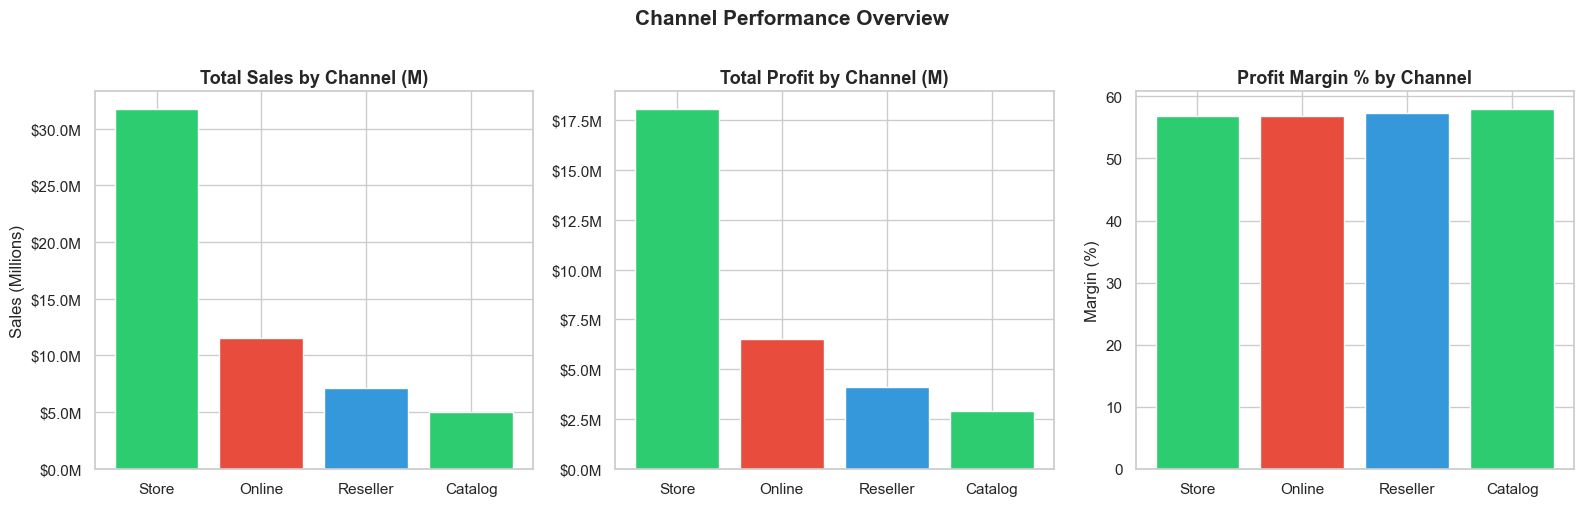

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Sales by Channel
axes[0].bar(channel['Channel'], channel['Total_Sales']/1e6, color=['#2ecc71','#e74c3c','#3498db'])
axes[0].set_title('Total Sales by Channel (M)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales (Millions)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}M'))

# Profit by Channel
axes[1].bar(channel['Channel'], channel['Total_Profit']/1e6, color=['#2ecc71','#e74c3c','#3498db'])
axes[1].set_title('Total Profit by Channel (M)', fontsize=13, fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}M'))

# Profit Margin
axes[2].bar(channel['Channel'], channel['Profit_Margin'], color=['#2ecc71','#e74c3c','#3498db'])
axes[2].set_title('Profit Margin % by Channel', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Margin (%)')
for ax in axes:
    ax.set_xlabel('')
plt.suptitle('Channel Performance Overview', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 5. Regional Sales Analysis

In [7]:
region = df.groupby('Region').agg(
    Orders=('Order ID','count'),
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum')
).reset_index().sort_values('Total_Sales', ascending=False)
print(region.to_string(index=False))

       Region  Orders  Total_Sales  Total_Profit
North America    8869 3.278356e+07  1.866883e+07
         Asia    3050 1.241235e+07  7.144694e+06
       Europe    3081 1.019586e+07  5.773913e+06


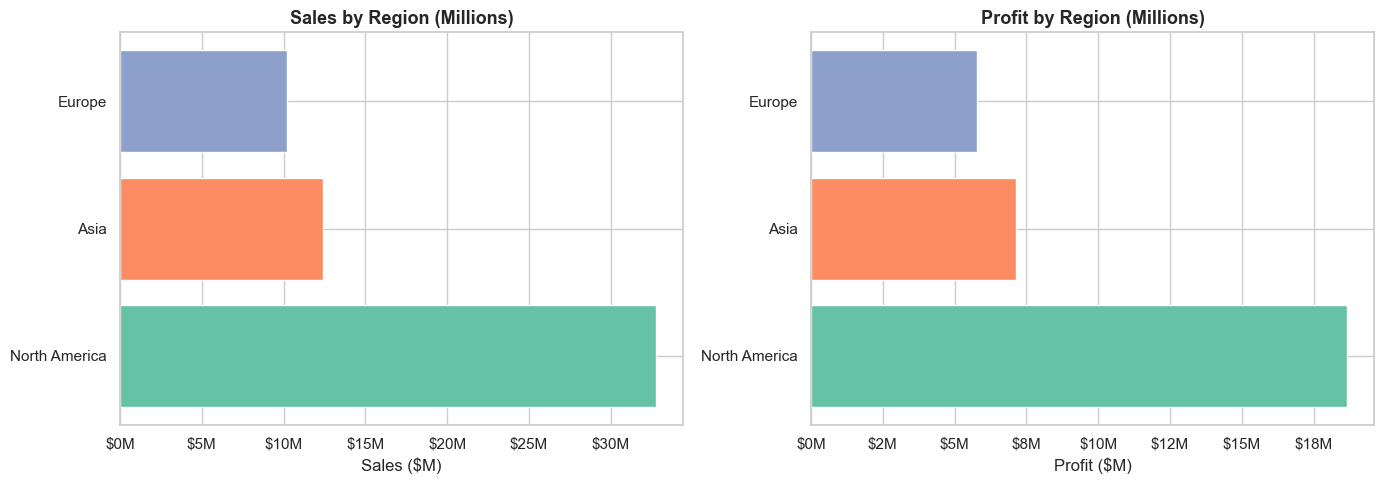

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = sns.color_palette('Set2', len(region))
axes[0].barh(region['Region'], region['Total_Sales']/1e6, color=colors)
axes[0].set_title('Sales by Region (Millions)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sales ($M)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

axes[1].barh(region['Region'], region['Total_Profit']/1e6, color=colors)
axes[1].set_title('Profit by Region (Millions)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Profit ($M)')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

plt.tight_layout()
plt.show()

## 6. Product Category & Sub-Category Analysis

In [9]:
cat = df.groupby('Product Category').agg(
    Orders=('Order ID','count'),
    Sales=('Sales','sum'),
    Profit=('Profit','sum')
).reset_index().sort_values('Sales', ascending=False)
print(cat.to_string(index=False))

             Product Category  Orders        Sales       Profit
                    Computers    5359 2.130697e+07 1.216242e+07
      Cameras and camcorders     3590 1.704893e+07 1.010280e+07
                 TV and Video    1878 9.107839e+06 4.823735e+06
                  Cell phones    2609 5.841156e+06 3.285926e+06
Music, Movies and Audio Books     832 1.057480e+06 6.352851e+05
                        Audio     732 1.029381e+06 5.772703e+05


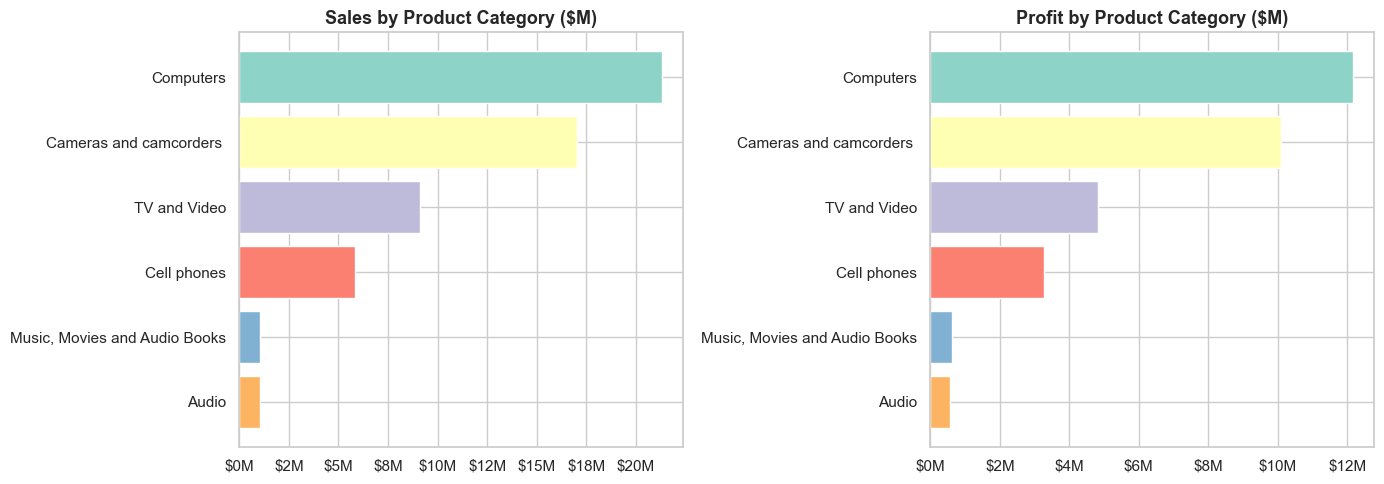

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(cat['Product Category'], cat['Sales']/1e6,
             color=sns.color_palette('Set3', len(cat)))
axes[0].set_title('Sales by Product Category ($M)', fontsize=13, fontweight='bold')
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

axes[1].barh(cat['Product Category'], cat['Profit']/1e6,
             color=sns.color_palette('Set3', len(cat)))
axes[1].set_title('Profit by Product Category ($M)', fontsize=13, fontweight='bold')
axes[1].invert_yaxis()
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

plt.tight_layout()
plt.show()

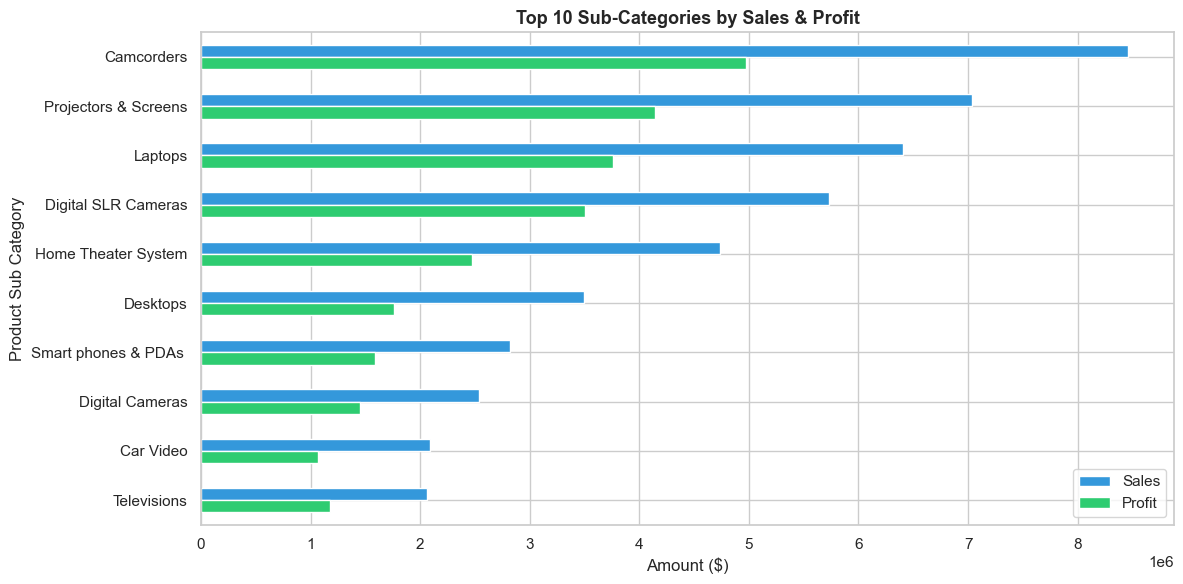

In [11]:
# Top 10 Sub-Categories by Sales
subcat = df.groupby('Product Sub Category')[['Sales','Profit']].sum().sort_values('Sales', ascending=False).head(10)
subcat.plot(kind='barh', figsize=(12,6), color=['#3498db','#2ecc71'])
plt.title('Top 10 Sub-Categories by Sales & Profit', fontsize=13, fontweight='bold')
plt.xlabel('Amount ($)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 7. Manufacturer Performance

In [12]:
mfr = df.groupby('Manufacturer').agg(
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Orders=('Order ID','count')
).sort_values('Sales', ascending=False).head(10)
print(mfr.to_string())

                             Sales        Profit  Orders
Manufacturer                                            
Fabrikam, Inc.        1.205428e+07  7.158977e+06    1605
Contoso, Ltd          9.996750e+06  5.670160e+06    4891
Adventure Works       7.467704e+06  4.158548e+06    1125
Proseware, Inc.       5.996829e+06  3.513125e+06    1639
Wide World Importers  5.700910e+06  3.198143e+06     990
A. Datum Corporation  4.404982e+06  2.608508e+06    1342
The Phone Company     4.386164e+06  2.476148e+06    1314
Southridge Video      3.112730e+06  1.610013e+06    1540
Litware, Inc.         2.134837e+06  1.120287e+06     348
Northwind Traders     1.365720e+05  7.352801e+04     206


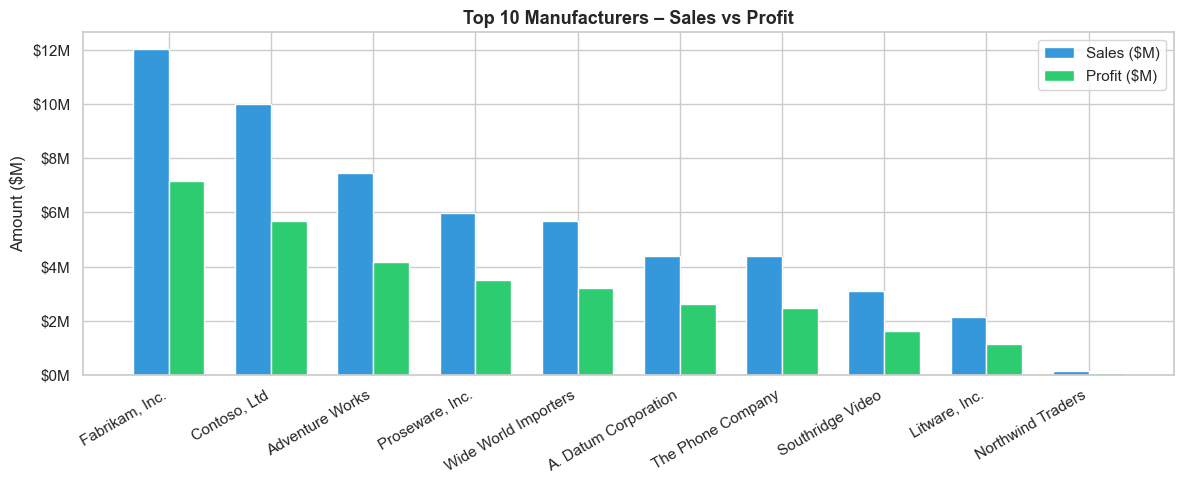

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(mfr))
w = 0.35
bars1 = ax.bar([i - w/2 for i in x], mfr['Sales']/1e6, w, label='Sales ($M)', color='#3498db')
bars2 = ax.bar([i + w/2 for i in x], mfr['Profit']/1e6, w, label='Profit ($M)', color='#2ecc71')
ax.set_xticks(list(x))
ax.set_xticklabels(mfr.index, rotation=30, ha='right')
ax.set_title('Top 10 Manufacturers – Sales vs Profit', fontsize=13, fontweight='bold')
ax.set_ylabel('Amount ($M)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}M'))
ax.legend()
plt.tight_layout()
plt.show()

## 8. Promotion Effectiveness

In [14]:
promo = df.groupby('Promotion Name').agg(
    Orders=('Order ID','count'),
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Avg_Order_Value=('Sales','mean')
).sort_values('Sales', ascending=False)
print(promo.to_string())

                                        Orders         Sales        Profit  Avg_Order_Value
Promotion Name                                                                             
No Discount                               5207  1.832936e+07  1.060415e+07      3520.138289
North America Back-to-School Promotion    2040  8.455761e+06  4.800290e+06      4144.980871
North America Holiday Promotion           1415  6.451629e+06  3.574758e+06      4559.455063
North America Spring Promotion            2079  6.374333e+06  3.566777e+06      3066.057273
Asian Holiday Promotion                    750  3.615194e+06  2.078391e+06      4820.258654
European Holiday Promotion                1025  3.083456e+06  1.745371e+06      3008.249711
European Spring Promotion                  721  2.739319e+06  1.498236e+06      3799.332839
Asian Spring Promotion                     745  2.396001e+06  1.411800e+06      3216.108271
Asian Summer Promotion                     498  2.278683e+06  1.315490e+06      

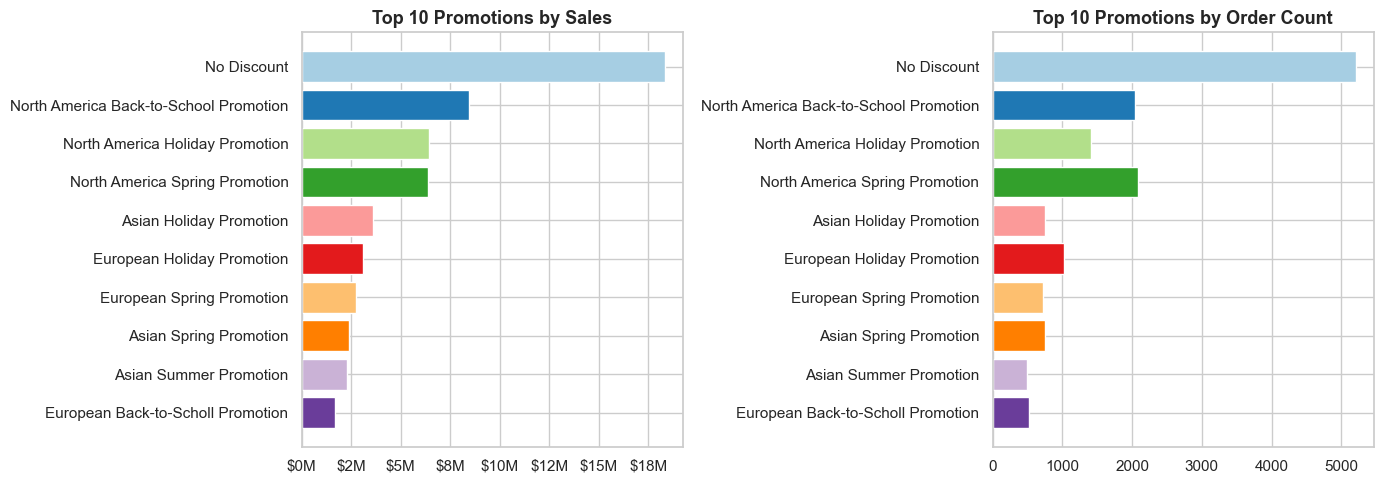

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

promo_top = promo.head(10)
axes[0].barh(promo_top.index, promo_top['Sales']/1e6, color=sns.color_palette('Paired', 10))
axes[0].set_title('Top 10 Promotions by Sales', fontsize=13, fontweight='bold')
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

axes[1].barh(promo_top.index, promo_top['Orders'], color=sns.color_palette('Paired', 10))
axes[1].set_title('Top 10 Promotions by Order Count', fontsize=13, fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## 9. Sales & Profit Trends Over Time

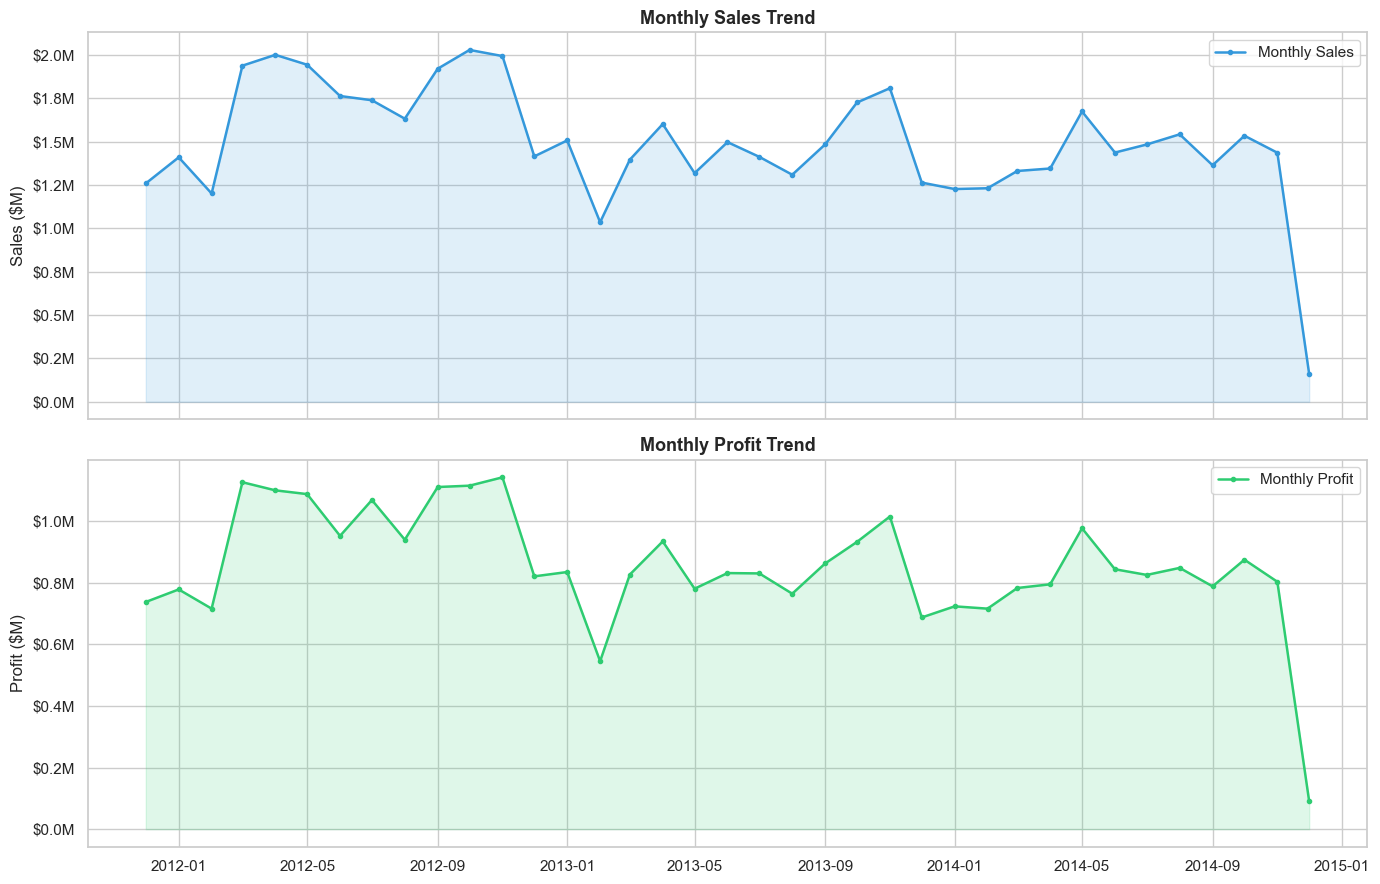

In [16]:
monthly = df.groupby(['Year','Month'])[['Sales','Profit']].sum().reset_index()
monthly['Period'] = pd.to_datetime(monthly[['Year','Month']].assign(day=1))
monthly = monthly.sort_values('Period')

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(monthly['Period'], monthly['Sales']/1e6, marker='o', markersize=3,
             color='#3498db', linewidth=1.8, label='Monthly Sales')
axes[0].fill_between(monthly['Period'], monthly['Sales']/1e6, alpha=0.15, color='#3498db')
axes[0].set_title('Monthly Sales Trend', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales ($M)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}M'))
axes[0].legend()

axes[1].plot(monthly['Period'], monthly['Profit']/1e6, marker='o', markersize=3,
             color='#2ecc71', linewidth=1.8, label='Monthly Profit')
axes[1].fill_between(monthly['Period'], monthly['Profit']/1e6, alpha=0.15, color='#2ecc71')
axes[1].set_title('Monthly Profit Trend', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Profit ($M)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}M'))
axes[1].legend()

plt.tight_layout()
plt.show()

In [17]:
# Year-over-Year comparison
yearly = df.groupby('Year')[['Sales','Profit','Order Qty']].sum().reset_index()
yearly['Profit_Margin_%'] = yearly['Profit']/yearly['Sales']*100
print(yearly.to_string(index=False))

 Year        Sales       Profit  Order Qty  Profit_Margin_%
 2011 1.259710e+06 7.371398e+05       5359        58.516638
 2012 2.099365e+07 1.194947e+07      81150        56.919449
 2013 1.736657e+07 9.838662e+06      73751        56.652875
 2014 1.577183e+07 9.062167e+06      90866        57.457926


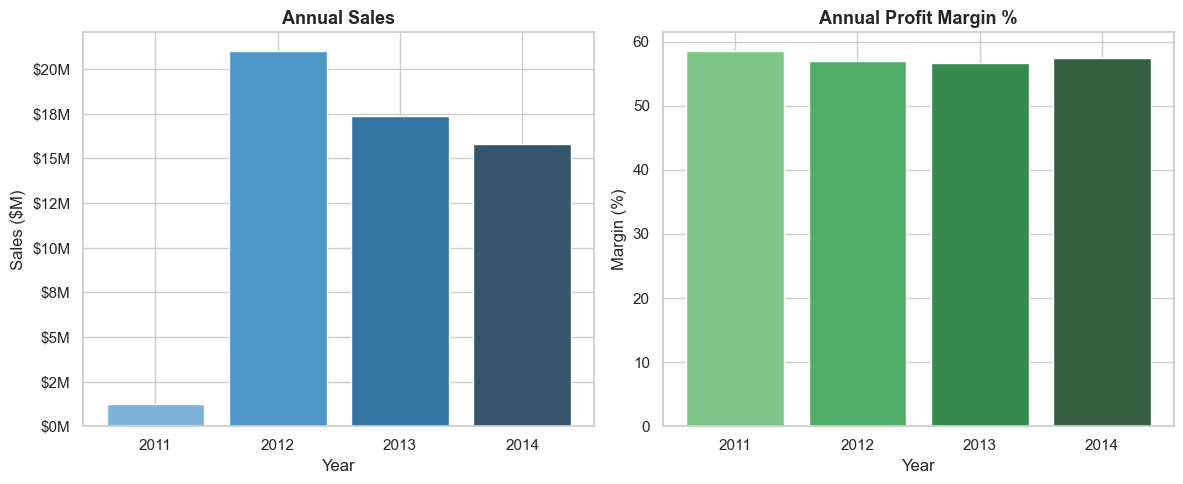

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
years = yearly['Year'].astype(str)

axes[0].bar(years, yearly['Sales']/1e6, color=sns.color_palette('Blues_d', len(years)))
axes[0].set_title('Annual Sales', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sales ($M)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

axes[1].bar(years, yearly['Profit_Margin_%'], color=sns.color_palette('Greens_d', len(years)))
axes[1].set_title('Annual Profit Margin %', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Margin (%)')
for ax in axes:
    ax.set_xlabel('Year')
plt.tight_layout()
plt.show()

## 10. Quarterly Sales Seasonality

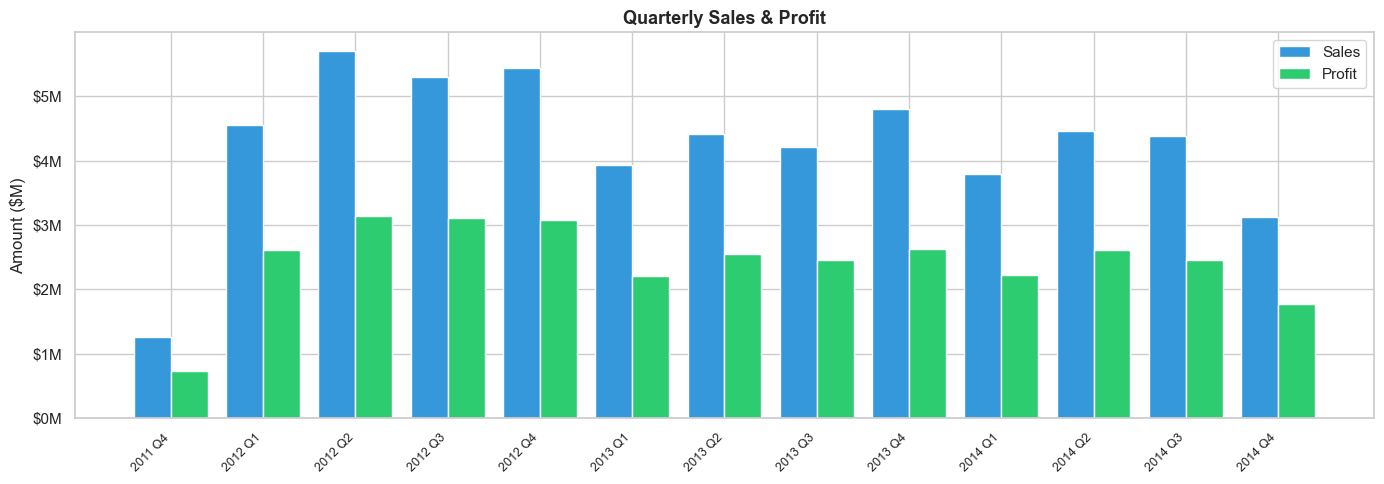

In [19]:
quarterly = df.groupby(['Year','Quarter'])[['Sales','Profit']].sum().reset_index()
quarterly['Period'] = quarterly['Year'].astype(str) + ' Q' + quarterly['Quarter'].astype(str)

fig, ax = plt.subplots(figsize=(14, 5))
x = range(len(quarterly))
ax.bar([i - 0.2 for i in x], quarterly['Sales']/1e6, 0.4, label='Sales', color='#3498db')
ax.bar([i + 0.2 for i in x], quarterly['Profit']/1e6, 0.4, label='Profit', color='#2ecc71')
ax.set_xticks(list(x))
ax.set_xticklabels(quarterly['Period'], rotation=45, ha='right', fontsize=9)
ax.set_title('Quarterly Sales & Profit', fontsize=13, fontweight='bold')
ax.set_ylabel('Amount ($M)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}M'))
ax.legend()
plt.tight_layout()
plt.show()

## 11. Distribution Analysis

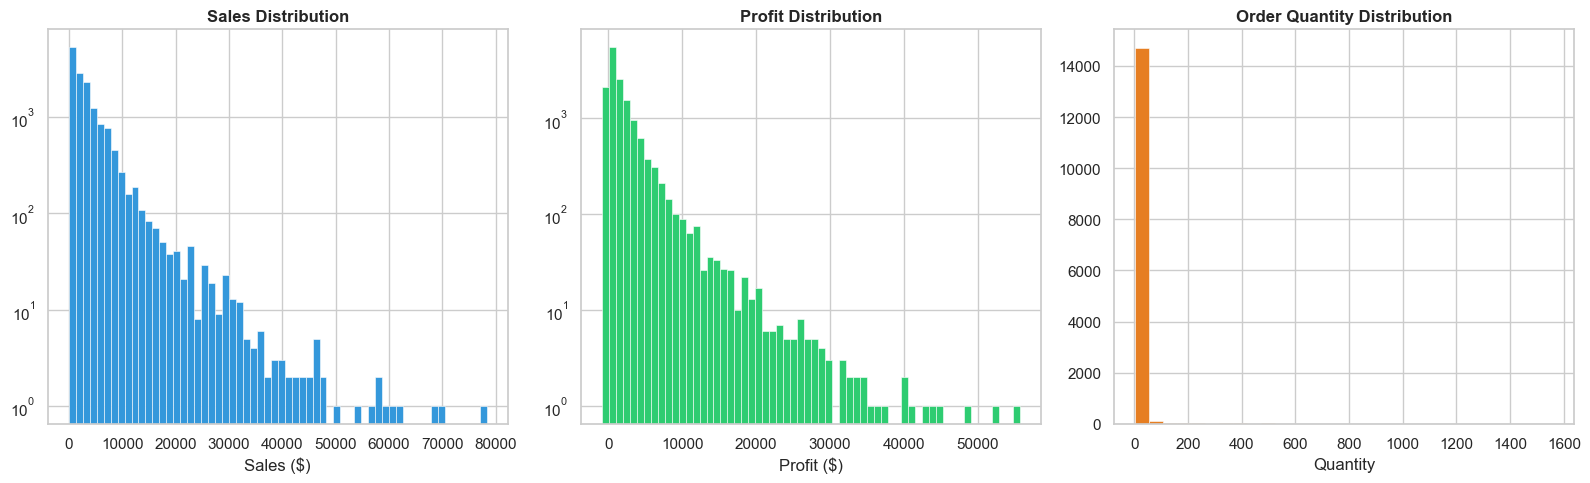

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].hist(df['Sales'], bins=60, color='#3498db', edgecolor='white', linewidth=0.4)
axes[0].set_title('Sales Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sales ($)')
axes[0].set_yscale('log')

axes[1].hist(df['Profit'], bins=60, color='#2ecc71', edgecolor='white', linewidth=0.4)
axes[1].set_title('Profit Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Profit ($)')
axes[1].set_yscale('log')

axes[2].hist(df['Order Qty'], bins=30, color='#e67e22', edgecolor='white', linewidth=0.4)
axes[2].set_title('Order Quantity Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Quantity')

plt.tight_layout()
plt.show()

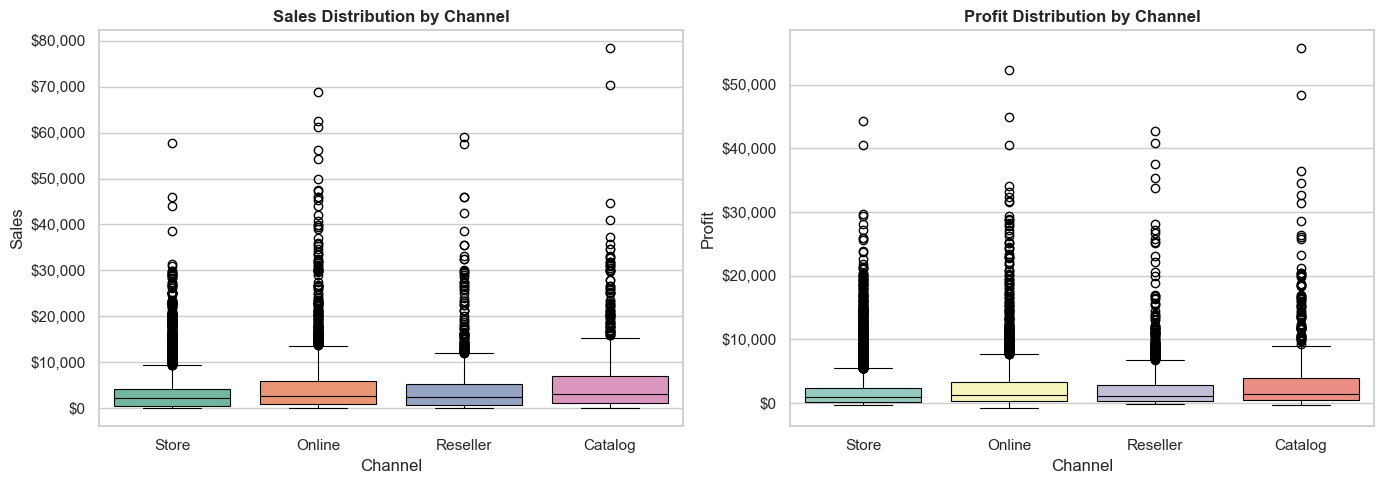

In [21]:
# Boxplot: Sales by Channel
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Channel', y='Sales', ax=axes[0],
            linecolor='black', linewidth=0.8, palette='Set2')
axes[0].set_title('Sales Distribution by Channel', fontsize=12, fontweight='bold')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

sns.boxplot(data=df, x='Channel', y='Profit', ax=axes[1],
            linecolor='black', linewidth=0.8, palette='Set3')
axes[1].set_title('Profit Distribution by Channel', fontsize=12, fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.show()

## 12. Correlation Analysis

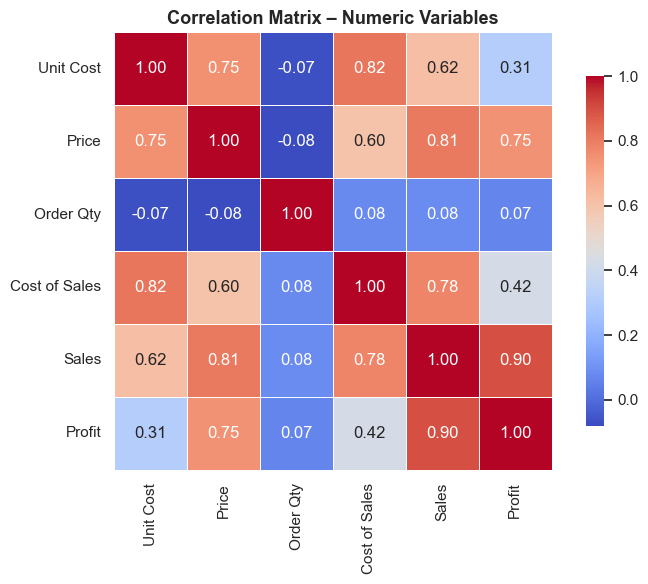

In [22]:
num_cols = ['Unit Cost','Price','Order Qty','Cost of Sales','Sales','Profit']
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax,
            linewidths=0.5, square=True, cbar_kws={'shrink':0.8})
ax.set_title('Correlation Matrix – Numeric Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 13. Top 15 Products by Sales

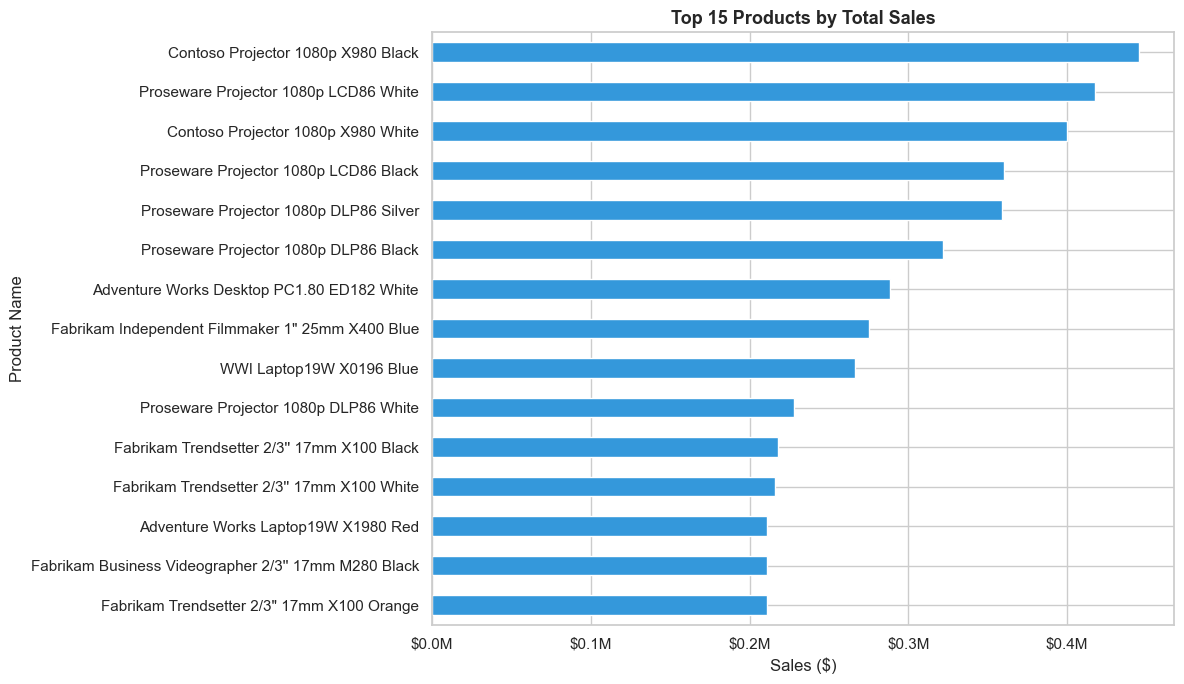

In [23]:
top_products = df.groupby('Product Name')[['Sales','Profit']].sum().sort_values('Sales', ascending=False).head(15)
fig, ax = plt.subplots(figsize=(12, 7))
top_products['Sales'].plot(kind='barh', ax=ax, color='#3498db', label='Sales')
ax.invert_yaxis()
ax.set_title('Top 15 Products by Total Sales', fontsize=13, fontweight='bold')
ax.set_xlabel('Sales ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.tight_layout()
plt.show()

## 14. Geographic Analysis – Top Countries & Cities

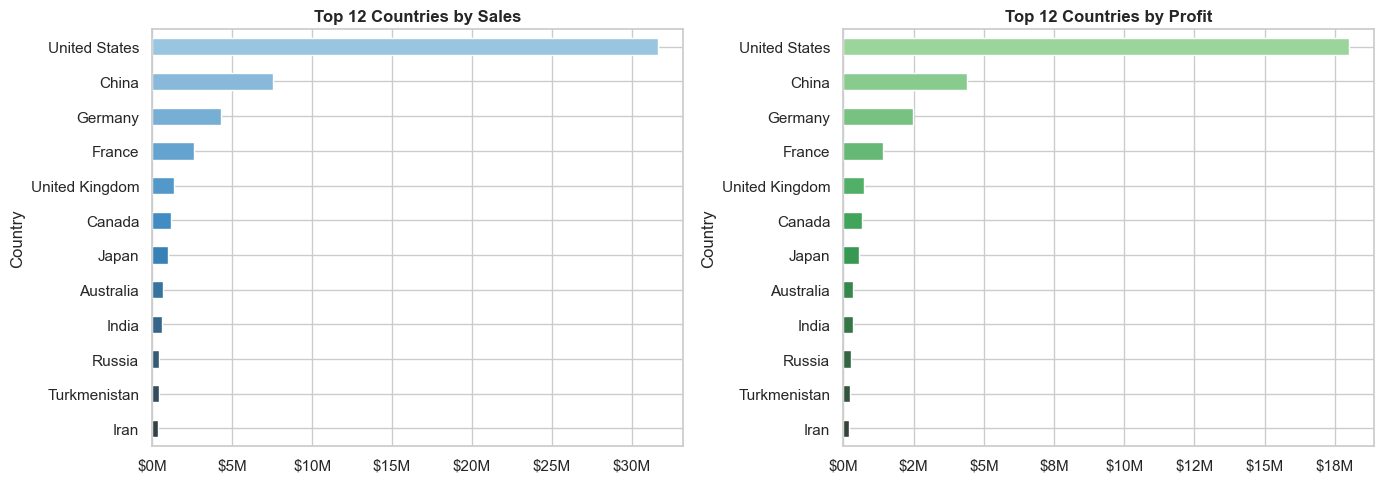

In [24]:
top_countries = df.groupby('Country')[['Sales','Profit']].sum().sort_values('Sales', ascending=False).head(12)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_countries['Sales'].plot(kind='barh', ax=axes[0], color=sns.color_palette('Blues_d', 12))
axes[0].invert_yaxis()
axes[0].set_title('Top 12 Countries by Sales', fontsize=12, fontweight='bold')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))

top_countries['Profit'].plot(kind='barh', ax=axes[1], color=sns.color_palette('Greens_d', 12))
axes[1].invert_yaxis()
axes[1].set_title('Top 12 Countries by Profit', fontsize=12, fontweight='bold')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))

plt.tight_layout()
plt.show()

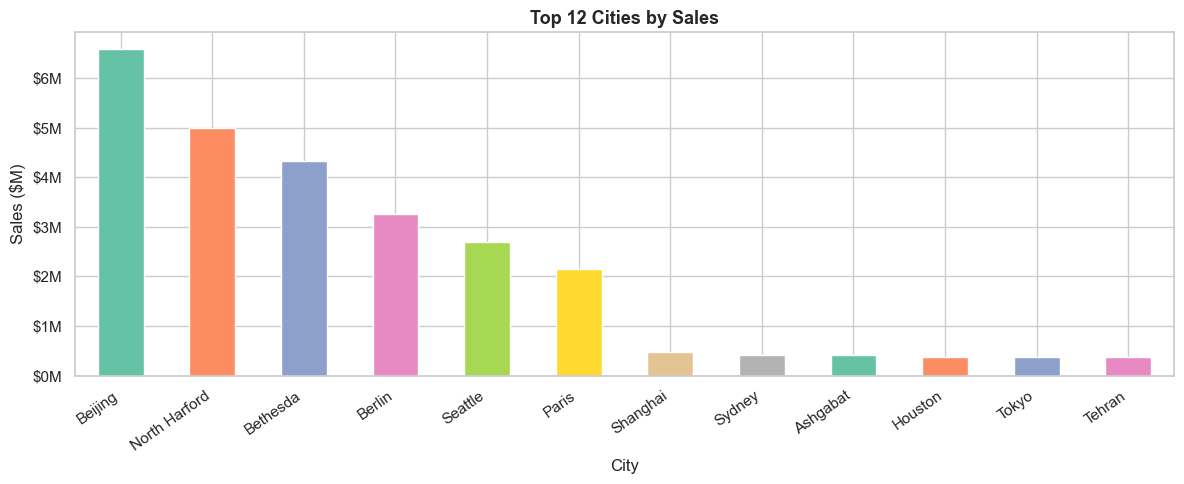

In [25]:
top_cities = df.groupby('City')[['Sales','Profit']].sum().sort_values('Sales', ascending=False).head(12)
fig, ax = plt.subplots(figsize=(12, 5))
top_cities['Sales'].plot(kind='bar', ax=ax, color=sns.color_palette('Set2', 12))
ax.set_title('Top 12 Cities by Sales', fontsize=13, fontweight='bold')
ax.set_xlabel('City')
ax.set_ylabel('Sales ($M)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 15. Executive Summary

In [26]:
total_sales   = df['Sales'].sum()
total_profit  = df['Profit'].sum()
margin        = total_profit / total_sales * 100
top_channel   = df.groupby('Channel')['Sales'].sum().idxmax()
top_region    = df.groupby('Region')['Sales'].sum().idxmax()
top_category  = df.groupby('Product Category')['Sales'].sum().idxmax()
top_country   = df.groupby('Country')['Sales'].sum().idxmax()
top_promo     = df.groupby('Promotion Name')['Sales'].sum().idxmax()

print("=" * 55)
print("          TRAINING SALES DATASET — KEY INSIGHTS")
print("=" * 55)
print(f"  Total Records      : {len(df):,}")
print(f"  Total Sales        : ${total_sales:,.0f}")
print(f"  Total Profit       : ${total_profit:,.0f}")
print(f"  Overall Margin     : {margin:.1f}%")
print(f"  Top Channel        : {top_channel}")
print(f"  Top Region         : {top_region}")
print(f"  Top Category       : {top_category}")
print(f"  Top Country        : {top_country}")
print(f"  Best Promotion     : {top_promo}")
print(f"  Date Range         : {df['Order Date'].min().date()} – {df['Order Date'].max().date()}")
print(f"  Unique Products    : {df['Product Name'].nunique()}")
print(f"  Unique Cities      : {df['City'].nunique()}")
print("=" * 55)

          TRAINING SALES DATASET — KEY INSIGHTS
  Total Records      : 15,000
  Total Sales        : $55,391,760
  Total Profit       : $31,587,437
  Overall Margin     : 57.0%
  Top Channel        : Store
  Top Region         : North America
  Top Category       : Computers
  Top Country        : United States
  Best Promotion     : No Discount
  Date Range         : 2011-12-06 – 2014-12-05
  Unique Products    : 1638
  Unique Cities      : 263
